# v10 — Data wearable Icentia11k untuk cabang bentuk gelombang EKG

**Pertanyaan.** v9 membuktikan bentuk gelombang memisahkan sinus takikardia dari AFL di Chapman (EKG klinis istirahat), tetapi
model yang sama gagal di AFDB (Holter): AFL palsu melonjak, 08378 hilang, bias kelas melompat ke kedua batas grid. Batasnya
**pergeseran domain**. Perangkat SIHEDAF adalah wearable satu lead, jadi domain yang relevan adalah rekaman rawat jalan.
**Apakah menambah data wearable rawat jalan (Icentia11k: patch EKG satu lead, 11.000 pasien, ratusan pasien AFL, aktivitas
harian) membuat model bentuk gelombang bekerja di AFDB tanpa kehilangan keunggulannya di Chapman?**

**Data Icentia11k** (PhysioNet `icentia11k-continuous-ecg` 1.0, CC BY-NC-SA 4.0, **hanya untuk akademik/riset**):
- semua file anotasi dibaca untuk mencari pasien AFL, AFIB, dan Normal (durasi tiap ritme per segmen);
- semua pasien AFL dipakai; 800 pasien AFIB dan 1.200 pasien Normal diambil acak (seed tetap);
- segmen diproses dengan front-end produksi (50 Hz, detektor R-peak v2) dan praproses EKG v6, seperti AFDB;
- per pasien paling banyak 120 window AFL, 40 AFIB, 20 Normal acak + 12 Normal tambahan ≥ 100 bpm (sinus takikardia asli
  saat beraktivitas). Window tambahan ini ikut dilatih, tetapi metrik 3 kelas Icentia hanya memakai window acak.

**Varian** (resep training v9 tanpa perubahan, fold AFDB resmi, fold Chapman v8, fold pasien Icentia baru):

| Varian | Model & data latih | Hipotesis (ditetapkan sebelum melihat hasil) |
|---|---|---|
| `rr` kontrol | MicroTransformer RR; AFDB + Chapman + Icentia | Ambang uji stres sintetis naik (> 115 bpm), AFL AFDB tidak membaik vs kontrol rr v9 |
| **`dual` 10a (utama)** | CNN EKG + RR; AFDB + Chapman + Icentia | vs 9a di AFDB: Macro-F1 naik (P ≥ 0,95), AFL palsu turun, bias AFL tidak di batas grid, 08378 kembali ≥ 0,78. Di Icentia: lebih baik dari 9a & paket v3.1. Di Chapman: alarm ST tetap ≤ 5% |
| `dual_tanpa_afdb` 10b | CNN EKG + RR; Chapman + Icentia saja (1 ulangan) | Eksploratif: AFDB = domain yang tidak pernah dilihat. Macro-F1 AFDB tidak lebih buruk dari v31 (P > 0,05)? |

**Pembanding:** v31 (v8), 9a dan kontrol rr v9 (OOF v9; bobot modelnya dipakai untuk memprediksi pasien Icentia), paket v3.1.

**Kriteria kandidat produksi untuk 10a (ditetapkan sebelum hasil).**
1. AFDB: Macro-F1 vs v31 tidak lebih buruk (P > 0,05) dan tidak ada pasien AFL yang turun ≥ 0,20.
2. Chapman: alarm sinus takikardia ≤ separuh paket v3.1; recall AFL Shaoxing tidak lebih rendah dari paket v3.1.
3. Icentia: alarm pada window Normal ≥ 120 bpm ≤ 25%; recall AFL tidak lebih rendah dari paket v3.1.
4. Bila lolos: protokol butir 10 (bootstrap bersarang, tanpa 04936) sebelum dikemas. Model yang dilatih dengan Icentia
   terikat lisensi non-komersial (keputusan pemilik produk).

**Prasyarat.** `../cache/v8/` (window Chapman, OOF & bobot v31), `../cache/v9/` (OOF & bobot 9a/rr), dan data Icentia
`../cache/v10/icentia_*` (dibuat sekali dengan `icentia.scan_icentia/select_segments/build_icentia_windows`, ±1 jam di
Kaggle CPU). Data mentah AFDB & Chapman diunduh ulang bila belum ada.

In [1]:
import os, sys, subprocess, time
from pathlib import Path
sys.path.insert(0, os.getcwd())
try:
    import wfdb  # noqa: F401
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "--progress-bar", "off", "wfdb"], check=True)
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

import icentia as I
C8, E6, G9, cv, T = I.C8, I.E6, I.G9, I.cv, I.T
pd.set_option("display.width", 230)
pd.set_option("display.max_columns", 30)
print("commit repo:", subprocess.run(["git", "log", "-1", "--format=%h %s"], capture_output=True, text=True).stdout.strip())
print(f"Python {sys.version.split()[0]} | torch {torch.__version__} | CPU {os.cpu_count()} | GPU",
      ", ".join(torch.cuda.get_device_name(i) for i in range(torch.cuda.device_count())) or "TIDAK ADA",
      "| QUICK" if I.QUICK else "")
for name, (_, oof, mdl, _) in I.REFS.items():
    assert Path(str(oof).format(r=0)).exists() and Path(str(mdl).format(r=0, k=0)).exists(), f"pembanding {name} tidak ada"


def fmt(v, nd=3):
    return f"{v[0]:.{nd}f} [{v[1]:.2f}–{v[2]:.2f}]"


def pct(v):
    return f"{v[0]:.0%} [{v[1]:.0%}–{v[2]:.0%}]"


def verdict(p):
    return "lebih baik" if p >= .95 else "lebih buruk" if p <= .05 else "tidak terbedakan"

commit repo: 51287fd feat(v9): cabang bentuk gelombang EKG dengan AFDB + Chapman (tidak dikemas)


Python 3.13.15 | torch 2.11.0+cu128 | CPU 4 | GPU Tesla T4, Tesla T4 


## 1. Data AFDB & Chapman

Sama dengan v9: AFDB & fold dibuktikan sama dengan tim, potongan EKG AFDB (v6) dan Chapman (lead II) dibuktikan sejajar dengan
window interval RR.

In [2]:
t0 = time.perf_counter()
print("AFDB:", C8.ensure_afdb()["identik_bit_demi_bit"], "| fold:", C8.ensure_folds().shape)
print("EKG AFDB:", G9.ensure_afdb_ecg())
if not G9.CH_ECG.exists():
    C8.download_chapman()
print("EKG Chapman:", G9.build_chapman_ecg())
ch = C8.load_chapman()
y_afdb = np.load(C8.DATA_STD)["y"]
print(f"selesai {time.perf_counter() - t0:.0f}s")

AFDB: True | fold: (5, 165978)


EKG AFDB: {'n': 165978, 'mismatch': 'cache'}


EKG Chapman: {'n': 42040, 'tidak_sejajar': 0}
selesai 2s


## 2. Data Icentia11k

Langkah 1: semua file anotasi dibaca (tidak disimpan) untuk menghitung durasi tiap ritme per segmen. Pembaca anotasi dibuktikan
sama dengan `wfdb.rdann`. Langkah 2: pasien & segmen dipilih dengan aturan tetap. Langkah 3: segmen terpilih diunduh (dicek
SHA256) dan dipotong menjadi window. Label window = ritme anotasi Icentia; window dipakai hanya bila semua detaknya berlabel sama.

In [3]:
t0 = time.perf_counter()
scan = I.scan_icentia()
sel = I.select_segments()
summ = I.icentia_summary() if I.IC_WIN.exists() else I.build_icentia_windows()
print(f"selesai {time.perf_counter() - t0:.0f}s")
print(f"Icentia11k: {scan['pasien']} pasien, {scan['segmen']} segmen, {scan['GB anotasi']:.1f} GB anotasi dibaca")
display(pd.DataFrame(scan["per ritme"]).T.rename_axis("ritme (anotasi)"))
print("kelompok pasien:", scan["kelompok pasien"], "| tidak dipakai:", scan["tanpa label ritme / tidak dipakai"])
print("terpilih:", sel["pasien"], "pasien,", len(sel["segmen"]), "segmen")
print("segmen:", summ["segmen"], "| kandidat window:", summ["kandidat window (sebelum dibatasi)"],
      "| kandidat Normal ≥ 100 bpm:", summ["kandidat Normal ≥ 100 bpm"])
display(pd.DataFrame(summ["per kelompok pasien"]).T.rename_axis("window dipakai"))
print(f"total {summ['window']} window, per kelas {summ['per kelas']}, termasuk {summ['Normal tambahan ≥ 100 bpm']} Normal tambahan ≥ 100 bpm")
display(pd.DataFrame({"AFDB (window)": np.bincount(y_afdb, minlength=3),
                      "Chapman andal (pasien)": np.bincount(ch["cls"][G9.train_mask(ch)], minlength=3),
                      "Icentia (window)": list(summ["per kelas"].values())}, index=list(I.CLASSES)))

selesai 2s
Icentia11k: 11000 pasien, 541794 segmen, 22.4 GB anotasi dibaca


,jam,episode,segmen,pasien
ritme (anotasi),,,,
(AFIB,23350.308594,848238.0,25218.0,747.0
(AFIB),1.440910,326.0,320.0,233.0
(AFL,8013.628418,313076.0,9657.0,519.0
(AFL),0.722878,175.0,169.0,111.0
(N,454034.781250,16074753.0,492370.0,10261.0
(N),62.779079,8405.0,8206.0,5101.0


kelompok pasien: {'Normal': 9637, 'AFIB': 710, 'AFL': 510} | tidak dipakai: 143
terpilih: {'AFL': 510, 'AFIB': 710, 'Normal': 1200} pasien, 4940 segmen
segmen: {'ok': 4940} | kandidat window: {'Normal': 1070704, 'AFIB': 983227, 'AFL': 1367699} | kandidat Normal ≥ 100 bpm: 42764


,Normal,AFIB,AFL,pasien
window dipakai,,,,
pasien AFL,5035,584,53253,510
pasien AFIB,2272,27149,0,710
pasien Normal,27429,0,0,1200


total 115722 window, per kelas {'Normal': 34736, 'AFIB': 27733, 'AFL': 53253}, termasuk 4435 Normal tambahan ≥ 100 bpm


,AFDB (window),Chapman andal (pasien),Icentia (window)
Normal,99000,32025,34736
AFIB,65826,1696,27733
AFL,1152,416,53253


**Cek label secara fisiologis** (pelajaran v8: label AFL Ningbo ternyata berperilaku seperti AFIB). AFL yang benar biasanya
lebih teratur daripada AFIB.

In [4]:
display(pd.DataFrame(I.label_check()).T.round(3))

,pasien,window,detak median,CV median,"CV > 0,10"
Normal (Icentia),1578.0,30301.0,70.093,0.034,0.215
AFIB (Icentia),729.0,27733.0,75.050,0.215,0.968
AFL (Icentia),509.0,53253.0,85.874,0.202,0.821
Normal (AFDB),21.0,99000.0,69.992,0.025,0.224
AFIB (AFDB),23.0,65826.0,90.500,0.213,0.966
AFL (AFDB),7.0,1152.0,139.168,0.030,0.181
"AFL (Icentia), pasien ≥ 50% window teratur",75.0,53253.0,NaN,NaN,NaN


**Catatan (ditulis sebelum training).** AFL Icentia berbeda dari AFL AFDB:
- AFDB: ±139 bpm dan teratur (CV 0,03), yaitu AFL 2:1;
- Icentia: ±86 bpm dan kebanyakan tidak teratur (CV 0,20; 82% window CV > 0,10). Dari sisi interval RR mirip AFIB, sesuai pola
  AFL dengan blok AV yang berubah-ubah. Hanya ±15% pasien AFL Icentia yang sebagian besar window AFL-nya teratur.

Berbeda dengan Ningbo (v8, tanpa satu pun AFIB), Icentia memberi label AFIB terpisah pada ±730 pasien dengan pola RR yang sama.
Jadi pelabel membedakan keduanya dari aktivitas atrium, bukan dari detak. Contoh di bawah juga memperlihatkan gelombang atrium
yang teratur di antara QRS. Karena itu label dipakai, dengan uji yang ditetapkan sekarang: **bila 10a memisahkan AFL dari AFIB
pada pasien Icentia uji jauh lebih baik daripada kontrol rr, label AFL Icentia memuat informasi atrium yang nyata.** Risikonya:
label semi-otomatis, dan AFL dengan AF kasar memang sering tertukar.

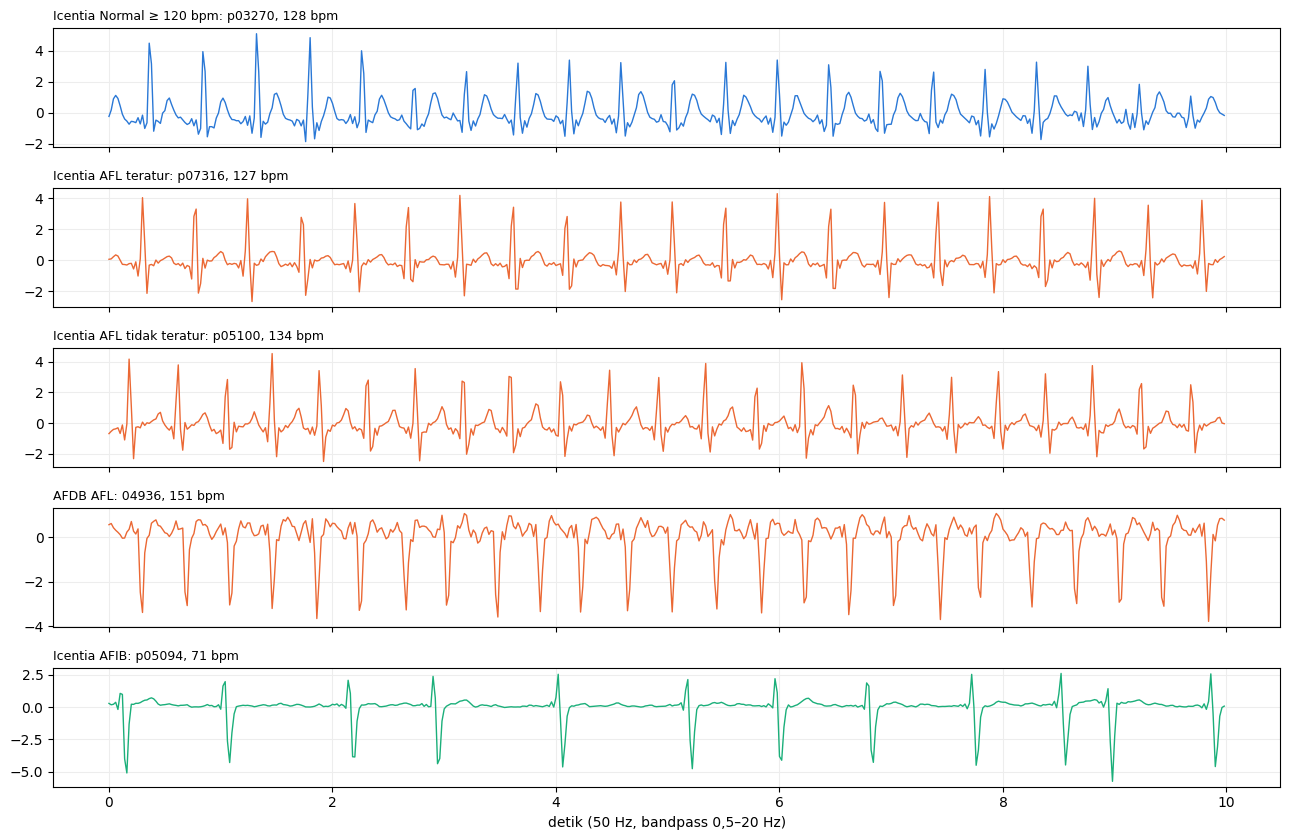

In [5]:
ic = I.load_icentia()
Ii = ic["X"][:, :, 0]; mi = (Ii * ic["M"]).sum(1) / ic["M"].sum(1)
cv_i = np.sqrt((((Ii - mi[:, None]) ** 2) * ic["M"]).sum(1) / ic["M"].sum(1)) / mi
Ea = np.load(E6.ECG_FILE)["ecg"]
za = np.load(C8.DATA_STD)
hr_a = 60000.0 / ((za["X"][:, :, 0] * za["M"]).sum(1) / za["M"].sum(1))
fig, axes = plt.subplots(5, 1, figsize=(13, 8.5), sharex=True)
tt = np.arange(E6.N_SAMP) / E6.FS
panels = [("Icentia Normal ≥ 120 bpm", ic["ecg"], (ic["y"] == 0) & (ic["hr"] >= 120), ic["patient"], ic["hr"], "#2a78d6"),
          ("Icentia AFL teratur", ic["ecg"], (ic["y"] == 2) & (ic["hr"] >= 120) & (cv_i <= 0.10), ic["patient"], ic["hr"], "#eb6834"),
          ("Icentia AFL tidak teratur", ic["ecg"], (ic["y"] == 2) & (cv_i > 0.10), ic["patient"], ic["hr"], "#eb6834"),
          ("AFDB AFL", Ea, (za["y"] == 2) & (hr_a >= 120), za["records"].astype(str), hr_a, "#eb6834"),
          ("Icentia AFIB", ic["ecg"], ic["y"] == 1, ic["patient"], ic["hr"], "#1baf7a")]
for ax, (title, E, m, who, hr, col) in zip(axes, panels):
    idx = np.flatnonzero(m)
    if not idx.size:
        ax.set_title(f"{title}: tidak ada", loc="left", fontsize=9); continue
    i = idx[len(idx) // 2]
    ax.plot(tt, E[i].astype(float), color=col, lw=1)
    ax.set_title(f"{title}: {who[i]}, {hr[i]:.0f} bpm", loc="left", fontsize=9)
    ax.grid(color="0.93")
axes[-1].set_xlabel("detik (50 Hz, bandpass 0,5–20 Hz)")
plt.tight_layout(); plt.show()

## 3. Training (10a & kontrol rr: 5 ulangan × 5 fold; 10b: 1 ulangan × 5 fold)

Fungsi training diimpor tanpa diubah: `ekg.train` (v6) untuk `dual`, `latih.train_dl_weighted` (v5) untuk `rr`. Satu proses per
GPU; job yang sudah ada dilewati. Sesudahnya bobot model pembanding (v8 v31, v9 rr & 9a) memprediksi pasien Icentia.

In [6]:
I.run_all_jobs()
I.predict_refs_icentia()

11 job tersisa dari 11, 2 proses (satu per GPU)


  [ 73.4 mnt] dual            ulangan 0: 876 s/fold
  [ 73.4 mnt] dual_tanpa_afdb ulangan 0: 407 s/fold


  [106.8 mnt] dual            ulangan 1: 863 s/fold


  [146.6 mnt] dual            ulangan 2: 876 s/fold


  [179.1 mnt] dual            ulangan 3: 865 s/fold


...

  [222.0 mnt] rr              ulangan 3: 128 s/fold


  [229.2 mnt] rr              ulangan 4: 112 s/fold


  prediksi Icentia v31: 5 ulangan


  prediksi Icentia v9_rr: 5 ulangan


  prediksi Icentia v9_dual: 5 ulangan


## 4. Hasil di AFDB (protokol v3)

Δ berpasangan terhadap v31 (referensi) dan terhadap 9a (data sama tanpa Icentia). Perhatikan rentang bias cross-fit: bias yang
melompat antar fold adalah tanda overfit per pasien (v6, v9).

In [7]:
t0 = time.perf_counter()
res = I.evaluate()
print(f"evaluasi {time.perf_counter() - t0:.0f}s")
lab = res["labels"]
A = res["afdb"]
order = [k for k in ("v1", "v31", "v9_rr", "v9_dual", "rr", "dual", "dual_tanpa_afdb") if k in A["rows"]]
display(pd.DataFrame([{"model": lab[k], **{m: fmt(A["rows"][k][m]) for m in ("Macro-F1", "AFL F1", "AFL R", "Normal R")},
                       "alarm AFL palsu/jam": fmt(A["episodes"][k]["alarm/jam"]),
                       "deteksi episode AFL": fmt(A["episodes"][k]["deteksi episode"], 2)} for k in order]).set_index("model"))
pr = []
for k in ("rr", "dual", "dual_tanpa_afdb"):
    for ref, P in (("v31", A["pairs"].get(k)), ("9a", A["pairs_9a"].get(k)), ("rr v9", A["pairs_9rr"].get(k))):
        if P is None:
            continue
        for m in ("Macro-F1", "AFL R", "Normal R"):
            pr.append({"model": lab[k], "vs": ref, "metrik": m, "Δ": round(P[m][0], 3), "CI 95%": f"{P[m][1]:+.3f} … {P[m][2]:+.3f}",
                       "P(Δ>0)": round(P[m][3], 3), "vonis": verdict(P[m][3])})
display(pd.DataFrame(pr).set_index(["model", "vs", "metrik"]))
display(pd.DataFrame({lab[k]: np.round(A["afl_recall"][k], 2) for k in order}, index=A["afl_patients"]).rename_axis("recall AFL"))
display(pd.DataFrame({lab[k]: {"AFL palsu/ulangan": round(A["fp"][k]["total"]), "dari pasien tanpa AFL": round(A["fp"][k]["pasien_lain"]),
                               "bias median": np.round(A["bias"][k]["median"], 2).tolist() if k in A["bias"] else "—",
                               "bias min…max (AFL)": (f"{A['bias'][k]['min'][2]:.2f} … {A['bias'][k]['max'][2]:.2f}" if k in A["bias"] else "—")}
                      for k in order}))

evaluasi 3001s


,Macro-F1,AFL F1,AFL R,Normal R,alarm AFL palsu/jam,deteksi episode AFL
model,,,,,,
"v31 (resep v3.1, AFDB saja; v8)",0.830 [0.67–0.92],0.647 [0.17–0.89],0.600 [0.14–0.93],0.920 [0.84–0.96],0.560 [0.16–1.08],0.77 [0.49–0.94]
kontrol rr v9 (AFDB + Chapman),0.783 [0.67–0.81],0.493 [0.15–0.57],0.436 [0.13–0.55],0.917 [0.84–0.96],0.640 [0.22–1.16],0.75 [0.49–0.91]
9a: EKG + RR v9 (AFDB + Chapman),0.687 [0.64–0.77],0.209 [0.02–0.45],0.404 [0.02–0.63],0.928 [0.88–0.97],2.655 [0.16–7.40],0.60 [0.24–0.84]
"kontrol: RR saja, AFDB + Chapman + Icentia",0.789 [0.66–0.83],0.514 [0.18–0.61],0.426 [0.11–0.58],0.904 [0.82–0.95],0.490 [0.14–0.98],0.78 [0.56–0.92]
"10a: CNN EKG + RR, AFDB + Chapman + Icentia",0.646 [0.61–0.67],0.101 [0.01–0.16],0.421 [0.05–0.60],0.940 [0.88–0.98],13.458 [6.09–22.86],0.65 [0.33–0.84]
"10b: CNN EKG + RR, Chapman + Icentia (AFDB tidak dilihat)",0.627 [0.60–0.65],0.064 [0.01–0.12],0.411 [0.07–0.56],0.962 [0.93–0.98],26.577 [16.30–38.26],0.71 [0.42–0.86]


Δ           CI 95%  P(Δ>0)             vonis
model                                              vs    metrik                                                    
kontrol: RR saja, AFDB + Chapman + Icentia         v31   Macro-F1 -0.042  -0.179 … +0.027   0.332  tidak terbedakan
                                                         AFL R    -0.174  -0.666 … +0.040   0.287  tidak terbedakan
                                                         Normal R -0.016  -0.031 … -0.006   0.000       lebih buruk
                                                   rr v9 Macro-F1  0.006  -0.032 … +0.028   0.632  tidak terbedakan
                                                         AFL R    -0.010  -0.105 … +0.033   0.404  tidak terbedakan
                                                         Normal R -0.013  -0.024 … -0.005   0.000       lebih buruk
10a: CNN EKG + RR, AFDB + Chapman + Icentia        v31   Macro-F1 -0.185  -0.290 … -0.019   0.011       lebih buruk
                                                         AFL R    -0.178  -0.867 … +0.189   0.297  tidak terbedakan
                                                         Normal R  0.020  -0.065 … +0.103   0.682  tidak terbedakan
                                                   9a    Macro-F1 -0.041  -0.133 … -0.001   0.018       lebih buruk
                                                         AFL R     0.017  -0.132 … +0.169   0.687  tidak terbedakan
                                                         Normal R  0.012  -0.036 … +0.059   0.689  tidak terbedakan
10b: CNN EKG + RR, Chapman + Icentia (AFDB tida... v31   Macro-F1 -0.204  -0.299 … -0.045   0.006       lebih buruk
                                                         AFL R    -0.189  -0.840 … +0.320   0.300  tidak terbedakan
                                                         Normal R  0.042  -0.014 … +0.112   0.925  tidak terbedakan
                                                   9a    Macro-F1 -0.060  -0.141 … -0.014   0.006       lebih buruk
                                                         AFL R     0.007  -0.106 … +0.298   0.538  tidak terbedakan
                                                         Normal R  0.034  -0.002 … +0.079   0.959        lebih baik

,"v31 (resep v3.1, AFDB saja; v8)",kontrol rr v9 (AFDB + Chapman),9a: EKG + RR v9 (AFDB + Chapman),"kontrol: RR saja, AFDB + Chapman + Icentia","10a: CNN EKG + RR, AFDB + Chapman + Icentia","10b: CNN EKG + RR, Chapman + Icentia (AFDB tidak dilihat)"
recall AFL,,,,,,
04043,0.60,0.80,0.00,0.60,0.60,0.00
04908,0.93,0.91,0.87,0.91,0.35,0.50
04936,0.51,0.52,0.62,0.55,0.62,0.56
06426,0.18,0.16,0.12,0.10,0.01,0.09
07910,0.00,0.00,0.07,0.02,0.39,0.57
08215,0.00,0.00,0.00,0.00,0.00,0.00
08378,0.98,0.35,0.00,0.23,0.04,0.05


,"v31 (resep v3.1, AFDB saja; v8)",kontrol rr v9 (AFDB + Chapman),9a: EKG + RR v9 (AFDB + Chapman),"kontrol: RR saja, AFDB + Chapman + Icentia","10a: CNN EKG + RR, AFDB + Chapman + Icentia","10b: CNN EKG + RR, Chapman + Icentia (AFDB tidak dilihat)"
AFL palsu/ulangan,293,313,2878,239,8245,13084
dari pasien tanpa AFL,33,66,49,50,4011,8775
bias median,"[0.0, -0.5, -4.5]","[0.0, 0.25, -1.5]","[0.0, 3.0, -7.0]","[0.0, 1.0, -1.0]","[0.0, 3.0, -7.0]","[0.0, 3.0, -7.0]"
bias min…max (AFL),-5.25 … -3.75,-2.50 … -0.25,-7.00 … 3.00,-2.50 … -0.25,-7.00 … -7.00,-7.00 … -7.00


## 5. Hasil di Icentia (pasien wearable yang tidak ikut dilatih)

Bias kelas dari AFDB, seperti di produksi. Metrik 3 kelas memakai window acak; CI = bootstrap pasien (bertingkat per kelompok).

In [8]:
Ic = res["icentia"]
print("pasien:", Ic["n_pasien"], "| window metrik:", Ic["n_window_metrik"], "| ulangan eksternal:", res["n_ulangan_eksternal"])
ikeys = [k for k in ("v31_paket", "v31", "v9_rr", "v9_dual", "rr", "dual", "dual_tanpa_afdb") if k in Ic["rows"]]
display(pd.DataFrame([{"model": lab[k], **{m: fmt(Ic["rows"][k][m]) for m in ("Macro-F1", "AFL F1", "AFL R", "AFL P", "AFIB R", "Normal R")}}
                      for k in ikeys]).set_index("model"))
pr = []
for ref in ("v31_paket", "v9_dual"):
    for k in ("rr", "dual", "dual_tanpa_afdb"):
        for m in ("Macro-F1", "AFL R", "Normal R"):
            p = Ic["pairs"][ref][k][m]
            pr.append({"model": lab[k], "vs": lab[ref], "metrik": m, "Δ": round(p[0], 3), "CI 95%": f"{p[1]:+.3f} … {p[2]:+.3f}",
                       "P(Δ>0)": round(p[3], 3), "vonis": verdict(p[3])})
display(pd.DataFrame(pr).set_index(["model", "vs", "metrik"]))

pasien: {'Normal': 1200, 'AFIB': 710, 'AFL': 510} | window metrik: {'Normal': 30301, 'AFIB': 27733, 'AFL': 53253} | ulangan eksternal: {'v31': 5, 'v9_rr': 5, 'v9_dual': 5, 'rr': 5, 'dual': 5, 'dual_tanpa_afdb': 1}


,Macro-F1,AFL F1,AFL R,AFL P,AFIB R,Normal R
model,,,,,,
paket produksi v3.1,0.477 [0.47–0.49],0.097 [0.07–0.12],0.051 [0.04–0.07],0.904 [0.86–0.94],0.936 [0.93–0.95],0.905 [0.90–0.91]
"v31 (resep v3.1, AFDB saja; v8)",0.471 [0.46–0.48],0.093 [0.07–0.12],0.049 [0.04–0.06],0.903 [0.86–0.94],0.919 [0.91–0.93],0.908 [0.90–0.92]
kontrol rr v9 (AFDB + Chapman),0.468 [0.46–0.48],0.074 [0.06–0.09],0.039 [0.03–0.05],0.898 [0.85–0.93],0.935 [0.93–0.94],0.916 [0.91–0.92]
9a: EKG + RR v9 (AFDB + Chapman),0.473 [0.47–0.48],0.052 [0.04–0.06],0.027 [0.02–0.03],0.931 [0.90–0.95],0.946 [0.94–0.95],0.952 [0.95–0.96]
"kontrol: RR saja, AFDB + Chapman + Icentia",0.482 [0.47–0.49],0.089 [0.07–0.11],0.047 [0.04–0.06],0.891 [0.84–0.93],0.964 [0.96–0.97],0.898 [0.89–0.91]
"10a: CNN EKG + RR, AFDB + Chapman + Icentia",0.666 [0.65–0.68],0.503 [0.48–0.53],0.359 [0.34–0.38],0.844 [0.83–0.86],0.864 [0.85–0.88],0.972 [0.97–0.98]
"10b: CNN EKG + RR, Chapman + Icentia (AFDB tidak dilihat)",0.662 [0.65–0.67],0.486 [0.46–0.51],0.338 [0.31–0.36],0.867 [0.85–0.88],0.894 [0.88–0.91],0.974 [0.97–0.98]


Δ           CI 95%  P(Δ>0)        vonis
model                                              vs                               metrik                                               
kontrol: RR saja, AFDB + Chapman + Icentia         paket produksi v3.1              Macro-F1  0.005  +0.001 … +0.009   0.990   lebih baik
                                                                                    AFL R    -0.004  -0.009 … +0.001   0.044  lebih buruk
                                                                                    Normal R -0.006  -0.011 … -0.002   0.002  lebih buruk
10a: CNN EKG + RR, AFDB + Chapman + Icentia        paket produksi v3.1              Macro-F1  0.189  +0.175 … +0.202   1.000   lebih baik
                                                                                    AFL R     0.308  +0.285 … +0.331   1.000   lebih baik
                                                                                    Normal R  0.067  +0.059 … +0.076   1.000   lebih baik
10b: CNN EKG + RR, Chapman + Icentia (AFDB tida... paket produksi v3.1              Macro-F1  0.185  +0.170 … +0.199   1.000   lebih baik
                                                                                    AFL R     0.287  +0.261 … +0.310   1.000   lebih baik
                                                                                    Normal R  0.069  +0.061 … +0.078   1.000   lebih baik
kontrol: RR saja, AFDB + Chapman + Icentia         9a: EKG + RR v9 (AFDB + Chapman) Macro-F1  0.008  +0.001 … +0.016   0.981   lebih baik
                                                                                    AFL R     0.020  +0.011 … +0.030   1.000   lebih baik
                                                                                    Normal R -0.054  -0.063 … -0.046   0.000  lebih buruk
10a: CNN EKG + RR, AFDB + Chapman + Icentia        9a: EKG + RR v9 (AFDB + Chapman) Macro-F1  0.192  +0.181 … +0.203   1.000   lebih baik
                                                                                    AFL R     0.332  +0.311 … +0.352   1.000   lebih baik
                                                                                    Normal R  0.019  +0.015 … +0.023   1.000   lebih baik
10b: CNN EKG + RR, Chapman + Icentia (AFDB tida... 9a: EKG + RR v9 (AFDB + Chapman) Macro-F1  0.188  +0.176 … +0.200   1.000   lebih baik
                                                                                    AFL R     0.311  +0.289 … +0.333   1.000   lebih baik
                                                                                    Normal R  0.021  +0.016 … +0.026   1.000   lebih baik

### Alarm pada ritme Normal per pita detak (sinus takikardia asli saat beraktivitas) dan AFL per pasien

,window,pasien,paket produksi v3.1,"v31 (resep v3.1, AFDB saja; v8)",kontrol rr v9 (AFDB + Chapman),9a: EKG + RR v9 (AFDB + Chapman),"kontrol: RR saja, AFDB + Chapman + Icentia","10a: CNN EKG + RR, AFDB + Chapman + Icentia","10b: CNN EKG + RR, Chapman + Icentia (AFDB tidak dilihat)"
ditebak AFIB/AFL,,,,,,,,,
0–60 bpm,7185,732,10% [8%–11%],9% [8%–11%],9% [8%–11%],3% [2%–4%],14% [12%–16%],3% [2%–4%],3% [2%–3%]
60–100 bpm,21509,1463,8% [7%–8%],7% [7%–8%],7% [6%–8%],5% [4%–6%],8% [8%–9%],3% [2%–3%],3% [2%–3%]
100–110 bpm,4229,579,15% [13%–17%],18% [16%–20%],16% [14%–19%],9% [7%–11%],14% [12%–16%],5% [4%–6%],5% [3%–6%]
110–120 bpm,1207,292,51% [45%–57%],51% [46%–56%],26% [22%–30%],12% [9%–14%],19% [16%–23%],7% [5%–10%],8% [5%–10%]
120–130 bpm,440,120,78% [71%–86%],76% [67%–85%],41% [34%–48%],13% [9%–17%],37% [29%–46%],10% [7%–15%],10% [6%–15%]
130–140 bpm,136,54,96% [90%–100%],89% [81%–96%],67% [54%–81%],22% [14%–31%],62% [47%–78%],17% [10%–26%],18% [9%–28%]
140–150 bpm,26,16,96% [89%–100%],88% [77%–98%],85% [68%–97%],27% [9%–53%],66% [40%–89%],25% [6%–52%],31% [9%–60%]
150–∞ bpm,4,4,100% [100%–100%],100% [100%–100%],100% [100%–100%],70% [40%–100%],100% [100%–100%],70% [20%–100%],100% [100%–100%]


,window,paket produksi v3.1,"v31 (resep v3.1, AFDB saja; v8)",kontrol rr v9 (AFDB + Chapman),9a: EKG + RR v9 (AFDB + Chapman),"kontrol: RR saja, AFDB + Chapman + Icentia","10a: CNN EKG + RR, AFDB + Chapman + Icentia","10b: CNN EKG + RR, Chapman + Icentia (AFDB tidak dilihat)"
ditebak AFIB/AFL,,,,,,,,
pasien Normal,23942,9% [8%–10%],8% [8%–9%],7% [7%–8%],4% [4%–5%],9% [8%–10%],3% [2%–3%],2% [2%–3%]
pasien AFIB,1999,9% [6%–11%],9% [6%–11%],9% [6%–11%],4% [3%–6%],11% [8%–14%],3% [2%–5%],3% [2%–5%]
pasien AFL,4360,14% [12%–16%],14% [12%–16%],14% [11%–16%],6% [5%–8%],17% [14%–19%],4% [3%–6%],4% [3%–6%]


,window,paket produksi v3.1,"v31 (resep v3.1, AFDB saja; v8)",kontrol rr v9 (AFDB + Chapman),9a: EKG + RR v9 (AFDB + Chapman),"kontrol: RR saja, AFDB + Chapman + Icentia","10a: CNN EKG + RR, AFDB + Chapman + Icentia","10b: CNN EKG + RR, Chapman + Icentia (AFDB tidak dilihat)"
AFL terdeteksi,,,,,,,,
0–100 bpm,35618,0% [0%–0%],0% [0%–0%],0% [0%–0%],2% [1%–2%],0% [0%–1%],34% [31%–36%],32% [29%–35%]
100–130 bpm,11747,4% [2%–6%],4% [2%–5%],2% [1%–2%],2% [1%–2%],3% [2%–4%],34% [30%–37%],31% [27%–34%]
130–160 bpm,5197,32% [25%–39%],30% [24%–38%],31% [25%–38%],8% [5%–11%],31% [25%–37%],52% [46%–58%],49% [43%–55%]
160–∞ bpm,691,89% [82%–94%],86% [78%–92%],34% [27%–45%],29% [19%–38%],69% [62%–77%],68% [56%–78%],71% [57%–83%]


,window,paket produksi v3.1,"v31 (resep v3.1, AFDB saja; v8)",kontrol rr v9 (AFDB + Chapman),9a: EKG + RR v9 (AFDB + Chapman),"kontrol: RR saja, AFDB + Chapman + Icentia","10a: CNN EKG + RR, AFDB + Chapman + Icentia","10b: CNN EKG + RR, Chapman + Icentia (AFDB tidak dilihat)"
ditebak sebagai,,,,,,,,
"teratur (CV ≤ 0,10)",9545,AFL 23% [17%–29%] | AFIB 20% [17%–24%],AFL 22% [17%–28%] | AFIB 20% [17%–24%],AFL 17% [13%–22%] | AFIB 15% [12%–18%],AFL 9% [7%–11%] | AFIB 33% [29%–38%],AFL 23% [18%–28%] | AFIB 16% [13%–18%],AFL 52% [46%–56%] | AFIB 17% [14%–20%],AFL 50% [45%–55%] | AFIB 17% [14%–20%]
"tidak teratur (CV > 0,10)",43708,AFL 1% [1%–2%] | AFIB 91% [90%–92%],AFL 1% [1%–1%] | AFIB 90% [89%–91%],AFL 1% [1%–1%] | AFIB 92% [90%–93%],AFL 1% [1%–2%] | AFIB 92% [91%–93%],AFL 1% [1%–1%] | AFIB 95% [94%–96%],AFL 33% [30%–35%] | AFIB 64% [61%–66%],AFL 30% [28%–33%] | AFIB 65% [63%–68%]


,pasien,median,"≥ 0,5",= 0
recall AFL per pasien (≥ 5 window AFL),,,,
paket produksi v3.1,499.0,0.000000,0.042084,0.741483
"v31 (resep v3.1, AFDB saja; v8)",499.0,0.000000,0.038076,0.671343
kontrol rr v9 (AFDB + Chapman),499.0,0.000000,0.024048,0.665331
9a: EKG + RR v9 (AFDB + Chapman),499.0,0.003333,0.002004,0.392786
"kontrol: RR saja, AFDB + Chapman + Icentia",499.0,0.000000,0.028056,0.573146
"10a: CNN EKG + RR, AFDB + Chapman + Icentia",499.0,0.318333,0.274549,0.006012
"10b: CNN EKG + RR, Chapman + Icentia (AFDB tidak dilihat)",499.0,0.275000,0.276553,0.042084


,pasien Normal,pasien AFIB,pasien AFL
AFL palsu (window/ulangan),,,
paket produksi v3.1,155,109,25
"v31 (resep v3.1, AFDB saja; v8)",151,108,22
kontrol rr v9 (AFDB + Chapman),103,126,15
9a: EKG + RR v9 (AFDB + Chapman),23,112,7
"kontrol: RR saja, AFDB + Chapman + Icentia",94,191,25
"10a: CNN EKG + RR, AFDB + Chapman + Icentia",158,3177,219
"10b: CNN EKG + RR, Chapman + Icentia (AFDB tidak dilihat)",164,2392,198


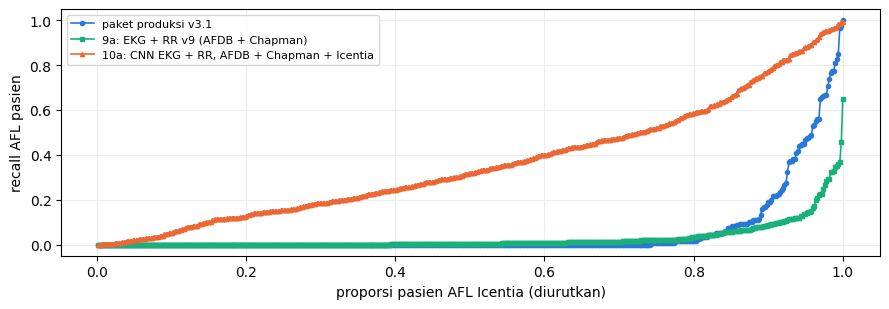

In [9]:
display(pd.DataFrame([{"Normal": f"{b} bpm", "window": v["n"], "pasien": v["pasien"], **{lab[k]: pct(v[k]) for k in ikeys}}
                      for b, v in Ic["normal_hr"].items()]).set_index("Normal").rename_axis("ditebak AFIB/AFL"))
display(pd.DataFrame([{"window Normal milik": f"pasien {g}", "window": v["n"], **{lab[k]: pct(v[k]) for k in ikeys}}
                      for g, v in Ic["normal_asal"].items()]).set_index("window Normal milik").rename_axis("ditebak AFIB/AFL"))
display(pd.DataFrame([{"AFL": f"{b} bpm", "window": v["n"], **{lab[k]: pct(v[k]) for k in ikeys}}
                      for b, v in Ic["afl_hr"].items()]).set_index("AFL").rename_axis("AFL terdeteksi"))
display(pd.DataFrame([{"AFL Icentia": g, "window": v["n"], **{lab[k]: f"AFL {pct(v['AFL'][k])} | AFIB {pct(v['AFIB'][k])}" for k in ikeys}}
                      for g, v in Ic["afl_cv"].items()]).set_index("AFL Icentia").rename_axis("ditebak sebagai"))
display(pd.DataFrame({lab[k]: Ic["afl_pasien"][k] for k in ikeys}).T.rename_axis("recall AFL per pasien (≥ 5 window AFL)"))
display(pd.DataFrame({lab[k]: {f"pasien {g}": round(v) for g, v in Ic["afl_palsu_asal"][k].items()} for k in ikeys}).T
        .rename_axis("AFL palsu (window/ulangan)"))
fig, ax = plt.subplots(figsize=(9, 3.2))
for k, col, mk in (("v31_paket", "#2a78d6", "o"), ("v9_dual", "#1baf7a", "s"), ("dual", "#eb6834", "^")):
    v = np.sort(Ic["afl_pasien_recall"][k])
    ax.plot(np.arange(1, v.size + 1) / v.size, v, color=col, marker=mk, ms=3, lw=1.2, label=lab[k])
ax.set_xlabel("proporsi pasien AFL Icentia (diurutkan)"); ax.set_ylabel("recall AFL pasien"); ax.grid(color="0.93"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## 6. Hasil di Chapman (label andal; sinus takikardia asli EKG klinis)

In [10]:
Cc = res["chapman"]
if Cc["paket_catatan"]:
    print("⚠", Cc["paket_catatan"])
print("pasien untuk metrik 3 kelas:", Cc["n_metrik"])
ckeys = [k for k in ("v31_paket", "v31", "v9_rr", "v9_dual", "rr", "dual", "dual_tanpa_afdb") if k in Cc["metrics"]]
display(pd.DataFrame([{"model": lab[k], **{m: fmt(Cc["metrics"][k][m]) for m in ("Macro-F1", "AFL F1", "AFL R", "AFIB R", "Normal R")}}
                      for k in ckeys]).set_index("model"))
pr = []
for ref in ("v31_paket", "v9_dual"):
    for k in ("rr", "dual", "dual_tanpa_afdb"):
        for m in ("Macro-F1", "AFL R", "Normal R"):
            p = Cc["pairs"][ref][k][m]
            pr.append({"model": lab[k], "vs": lab[ref], "metrik": m, "Δ": round(p[0], 3), "CI 95%": f"{p[1]:+.3f} … {p[2]:+.3f}",
                       "P(Δ>0)": round(p[3], 3), "vonis": verdict(p[3])})
display(pd.DataFrame(pr).set_index(["model", "vs", "metrik"]))
rows = [{"kelompok": f"ST {b} bpm", "pasien": v["n"], **{lab[k]: pct(v[k]) for k in ckeys}} for b, v in Cc["st_bands"].items()]
rows += [{"kelompok": "ST semua", "pasien": Cc["st_all"]["n"], **{lab[k]: pct(Cc["st_all"][k]) for k in ckeys}},
         {"kelompok": "SVT (alarm = bagus)", "pasien": Cc["svt_alarm"]["n"], **{lab[k]: pct(Cc["svt_alarm"][k]) for k in ckeys}}]
display(pd.DataFrame(rows).set_index("kelompok").rename_axis("ditebak AFIB/AFL"))

pasien untuk metrik 3 kelas: {'Normal': 32025, 'AFIB': 1696, 'AFL': 416}


,Macro-F1,AFL F1,AFL R,AFIB R,Normal R
model,,,,,
paket produksi v3.1,0.520 [0.51–0.53],0.078 [0.06–0.09],0.243 [0.20–0.28],0.953 [0.94–0.96],0.865 [0.86–0.87]
"v31 (resep v3.1, AFDB saja; v8)",0.531 [0.53–0.54],0.084 [0.07–0.10],0.232 [0.19–0.27],0.942 [0.93–0.95],0.882 [0.88–0.88]
kontrol rr v9 (AFDB + Chapman),0.594 [0.58–0.60],0.131 [0.10–0.16],0.136 [0.11–0.17],0.945 [0.94–0.95],0.951 [0.95–0.95]
9a: EKG + RR v9 (AFDB + Chapman),0.739 [0.73–0.75],0.348 [0.31–0.39],0.225 [0.19–0.26],0.968 [0.96–0.97],0.993 [0.99–0.99]
"kontrol: RR saja, AFDB + Chapman + Icentia",0.581 [0.57–0.59],0.122 [0.10–0.15],0.122 [0.10–0.15],0.968 [0.96–0.97],0.943 [0.94–0.95]
"10a: CNN EKG + RR, AFDB + Chapman + Icentia",0.769 [0.76–0.78],0.432 [0.40–0.46],0.348 [0.31–0.38],0.936 [0.93–0.94],0.994 [0.99–0.99]
"10b: CNN EKG + RR, Chapman + Icentia (AFDB tidak dilihat)",0.790 [0.77–0.81],0.490 [0.45–0.53],0.430 [0.38–0.48],0.926 [0.91–0.94],0.994 [0.99–1.00]


Δ           CI 95%  P(Δ>0)        vonis
model                                              vs                               metrik                                               
kontrol: RR saja, AFDB + Chapman + Icentia         paket produksi v3.1              Macro-F1  0.061  +0.053 … +0.069   1.000   lebih baik
                                                                                    AFL R    -0.121  -0.154 … -0.088   0.000  lebih buruk
                                                                                    Normal R  0.078  +0.075 … +0.081   1.000   lebih baik
10a: CNN EKG + RR, AFDB + Chapman + Icentia        paket produksi v3.1              Macro-F1  0.249  +0.235 … +0.261   1.000   lebih baik
                                                                                    AFL R     0.105  +0.058 … +0.150   1.000   lebih baik
                                                                                    Normal R  0.129  +0.126 … +0.133   1.000   lebih baik
10b: CNN EKG + RR, Chapman + Icentia (AFDB tida... paket produksi v3.1              Macro-F1  0.270  +0.254 … +0.286   1.000   lebih baik
                                                                                    AFL R     0.188  +0.125 … +0.248   1.000   lebih baik
                                                                                    Normal R  0.129  +0.126 … +0.133   1.000   lebih baik
kontrol: RR saja, AFDB + Chapman + Icentia         9a: EKG + RR v9 (AFDB + Chapman) Macro-F1 -0.158  -0.171 … -0.145   0.000  lebih buruk
                                                                                    AFL R    -0.104  -0.136 … -0.071   0.000  lebih buruk
                                                                                    Normal R -0.050  -0.052 … -0.048   0.000  lebih buruk
10a: CNN EKG + RR, AFDB + Chapman + Icentia        9a: EKG + RR v9 (AFDB + Chapman) Macro-F1  0.030  +0.017 … +0.043   1.000   lebih baik
                                                                                    AFL R     0.123  +0.091 … +0.152   1.000   lebih baik
                                                                                    Normal R  0.001  +0.000 … +0.001   1.000   lebih baik
10b: CNN EKG + RR, Chapman + Icentia (AFDB tida... 9a: EKG + RR v9 (AFDB + Chapman) Macro-F1  0.051  +0.034 … +0.068   1.000   lebih baik
                                                                                    AFL R     0.205  +0.160 … +0.251   1.000   lebih baik
                                                                                    Normal R  0.001  +0.000 … +0.002   0.995   lebih baik

,pasien,paket produksi v3.1,"v31 (resep v3.1, AFDB saja; v8)",kontrol rr v9 (AFDB + Chapman),9a: EKG + RR v9 (AFDB + Chapman),"kontrol: RR saja, AFDB + Chapman + Icentia","10a: CNN EKG + RR, AFDB + Chapman + Icentia","10b: CNN EKG + RR, Chapman + Icentia (AFDB tidak dilihat)"
ditebak AFIB/AFL,,,,,,,,
ST 100–110 bpm,3415,6% [6%–7%],6% [5%–7%],4% [3%–4%],1% [1%–1%],4% [4%–5%],1% [1%–1%],1% [0%–1%]
ST 110–120 bpm,1639,55% [52%–57%],41% [39%–43%],6% [5%–7%],1% [1%–1%],6% [5%–7%],1% [1%–1%],1% [0%–1%]
ST 120–130 bpm,783,98% [97%–99%],92% [91%–93%],11% [9%–12%],2% [1%–3%],10% [8%–12%],2% [1%–3%],2% [1%–3%]
ST 130–140 bpm,484,100% [100%–100%],99% [98%–99%],27% [25%–31%],3% [1%–4%],20% [17%–23%],3% [1%–4%],3% [1%–4%]
ST 140–150 bpm,199,100% [100%–100%],100% [99%–100%],70% [66%–75%],3% [1%–5%],54% [49%–60%],3% [1%–5%],3% [1%–5%]
ST 150–∞ bpm,277,100% [100%–100%],100% [100%–100%],43% [38%–48%],3% [1%–4%],63% [59%–67%],4% [2%–6%],4% [2%–6%]
ST semua,6937,42% [40%–43%],38% [37%–39%],11% [10%–12%],2% [1%–2%],11% [10%–12%],1% [1%–2%],1% [1%–2%]
SVT (alarm = bagus),556,99% [98%–100%],99% [98%–99%],39% [36%–43%],56% [53%–59%],45% [42%–48%],70% [67%–72%],74% [70%–77%]


## 7. Uji stres sintetis (model interval RR saja) dan sensitivitas tanpa 04936

In [11]:
display(pd.DataFrame({lab[k]: res["threshold"][k] for k in res["threshold"]}).T.rename_axis("ambang (bpm) < 50% Normal"))
sens = []
for lab_s, s in A["sens"].items():
    for k, r in s["rows"].items():
        sens.append({"data": lab_s, "model": lab[k], **{m: fmt(r[m]) for m in ("Macro-F1", "AFL F1", "AFL R")},
                     "P(v31 > model)": round(s["pairs_v31_minus"][k][3], 2) if k in s["pairs_v31_minus"] else "—"})
display(pd.DataFrame(sens).set_index(["data", "model"]))
display(pd.DataFrame({v: {"s/fold": round(res["train_time"][v]), "latih AFDB/Chapman/Icentia (window)":
                          " / ".join(str(int(sum(x))) for x in res["n_train"][v])} for v in I.VARIANTS}).T)

,tanpa variasi,seragam ±10 ms,Gauss sd 10 ms,Gauss sd 20 ms
ambang (bpm) < 50% Normal,,,,
"kontrol: RR saja, AFDB + Chapman + Icentia",140,135,135,135
"v31 (resep v3.1, AFDB saja; v8)",115,115,115,115
kontrol rr v9 (AFDB + Chapman),135,135,135,120


Macro-F1             AFL F1              AFL R P(v31 > model)
data         model                                                                                                                     
semua pasien v31 (resep v3.1, AFDB saja; v8)                     0.830 [0.67–0.92]  0.647 [0.17–0.89]  0.600 [0.14–0.93]              —
             kontrol rr v9 (AFDB + Chapman)                      0.783 [0.67–0.81]  0.493 [0.15–0.57]  0.436 [0.13–0.55]           0.84
             9a: EKG + RR v9 (AFDB + Chapman)                    0.687 [0.64–0.77]  0.209 [0.02–0.45]  0.404 [0.02–0.63]           0.93
             kontrol: RR saja, AFDB + Chapman + Icentia          0.789 [0.66–0.83]  0.514 [0.18–0.61]  0.426 [0.11–0.58]           0.67
             10a: CNN EKG + RR, AFDB + Chapman + Icentia         0.646 [0.61–0.67]  0.101 [0.01–0.16]  0.421 [0.05–0.60]           0.99
             10b: CNN EKG + RR, Chapman + Icentia (AFDB tida...  0.627 [0.60–0.65]  0.064 [0.01–0.12]  0.411 [0.07–0.56]           0.99
tanpa 04936  v31 (resep v3.1, AFDB saja; v8)                     0.859 [0.62–0.93]  0.734 [0.02–0.92]  0.689 [0.02–0.93]              —
             kontrol rr v9 (AFDB + Chapman)                      0.693 [0.62–0.80]  0.223 [0.02–0.54]  0.159 [0.02–0.68]           0.71
             9a: EKG + RR v9 (AFDB + Chapman)                    0.668 [0.63–0.70]  0.134 [0.02–0.23]  0.153 [0.01–0.76]           0.86
             kontrol: RR saja, AFDB + Chapman + Icentia          0.776 [0.63–0.83]  0.489 [0.06–0.62]  0.413 [0.05–0.55]           0.78
             10a: CNN EKG + RR, AFDB + Chapman + Icentia         0.628 [0.60–0.66]  0.027 [0.00–0.09]  0.141 [0.04–0.38]           0.94
             10b: CNN EKG + RR, Chapman + Icentia (AFDB tida...  0.619 [0.59–0.64]  0.019 [0.00–0.05]  0.199 [0.05–0.53]           0.97

,s/fold,latih AFDB/Chapman/Icentia (window)
rr,124,132782 / 27309 / 92577
dual,871,132782 / 27309 / 92577
dual_tanpa_afdb,407,0 / 27309 / 92577


In [12]:
I.CACHE_OUT.mkdir(parents=True, exist_ok=True)
(I.CACHE_OUT / "ringkasan.json").write_text(json.dumps(res, indent=1, ensure_ascii=False))
dest = Path("/kaggle/working/v10_hasil.zip") if Path("/kaggle/working").exists() else I.CACHE_OUT / "v10_hasil.zip"
path, mb = I.pack_results(dest)
print(f"Ringkasan → {I.CACHE_OUT.name}/ringkasan.json | hasil → {path} ({mb:.0f} MB)")

Ringkasan → v10/ringkasan.json | hasil → /kaggle/working/v10_hasil.zip (112 MB)


## 8. Kesimpulan

**Data wearable Icentia membuat model bentuk gelombang jauh lebih baik di dua domain eksternal (Icentia dan Chapman), tetapi lebih
buruk di AFDB. Paket produksi tetap v3.1; v10 tidak dikemas.**

- **Data.** Semua 541.794 file anotasi Icentia dibaca. Yang dipakai: 510 pasien AFL (AFDB hanya 7), 710 AFIB, 1.200 Normal, total
  115.722 window, semuanya sejajar dengan window RR (0 selisih). AFL Icentia kebanyakan AFL dengan blok bervariasi (86 bpm, CV 0,20),
  berbeda dari AFL 2:1 di AFDB (139 bpm, CV 0,03).
- **Icentia (2.420 pasien wearable yang tidak ikut dilatih):**
  - Macro-F1: 10a 0,666, paket v3.1 0,477, 9a 0,473 (P = 1,00);
  - recall AFL 0,359 vs 0,051 (paket); Normal R 0,972;
  - alarm pada window Normal ≥ 120 bpm: paket 83%, kontrol rr 44%, 9a 16%, **10a 13%**.
- **Uji label (ditetapkan sebelum hasil): terbukti.** Pada AFL Icentia yang tidak teratur, 10a menebak AFL 33%, sedangkan kontrol rr
  hanya 1% (95% ditebak AFIB). AFL F1: 0,503 vs 0,089. Label AFL Icentia memuat informasi atrium yang nyata.
- **Chapman:** Macro-F1 10a 0,769 vs 9a 0,739 (P = 1,00); recall AFL Shaoxing 0,348 vs 9a 0,225 dan paket 0,243 (keduanya P = 1,00);
  alarm sinus takikardia 1%.
- **AFDB (protokol v3):**
  - Macro-F1 10a 0,646 vs v31 0,830 (lebih buruk, P(Δ>0) = 0,01) dan vs 9a 0,687 (lebih buruk, P = 0,02);
  - AFL palsu 8.245 per ulangan, 95% dari window AFIB, 70% dari dua pasien (04936, 06995); alarm AFL palsu 13,5/jam;
  - recall AFL 08378 0,04 dan 04908 0,35; bias AFL −7 (batas bawah grid) di semua fold;
  - 07910, yang gagal di semua model v3–v9 (recall ≤ 0,07), kini 0,39 (10b 0,57).
- **Eksplorasi setelah hasil (bukan protokol):** grid bias yang diperlebar ke −15 tidak menolong (0,645). AUROC AFL-lawan-lain di AFDB
  turun dari 0,937 (v31) ke 0,905 (9a) dan 0,830 (10a), sedangkan AUROC AFIB tetap 0,95–0,98. Masalahnya pemisahan AFL dari AFIB, bukan
  kalibrasi.
- **10b (tanpa AFDB):** di Icentia setara 10a (0,662), di Chapman sedikit lebih tinggi (0,790); di AFDB 0,627 (lebih buruk dari v31, P = 0,006).
- **Kontrol rr:** ambang uji stres sintetis naik 115 → 135–140 bpm; di AFDB tidak terbedakan dari kontrol rr v9 (P = 0,63).
- **Hipotesis:** kontrol rr terbukti; 10a terbukti di Icentia dan Chapman, ditolak di AFDB; 10b ditolak.
- **Kriteria kandidat 10a:** Chapman lolos, Icentia lolos, AFDB **tidak lolos** (Macro-F1 lebih buruk; 04908 0,93 → 0,35;
  08378 0,98 → 0,04).

**Untuk proyek.** Batasnya bergeser lagi: bukan lagi jumlah pasien, melainkan **definisi AFL vs AFIB yang berbeda antar dataset**. Dari
Icentia, model belajar bahwa AFL bisa tidak teratur asalkan aktivitas atriumnya terorganisasi. Pola itu juga muncul pada banyak window
AFIB di AFDB (AF "kasar"). Tiga domain sekarang memberi vonis yang berlawanan. Domain mana yang mirip perangkat SIHEDAF tidak bisa
diketahui dari data publik.

**Langkah berikutnya.**
1. Validasi dengan rekaman perangkat SIHEDAF yang dilabeli dokter. Ini sekarang paling menentukan.
2. Minta ahli meninjau label AFIB/AFL pasien AFDB 04936 dan 06995 (sumber AFL palsu terbesar) serta contoh AFL Icentia yang tidak
   teratur.
3. Keputusan produk: apakah AFL perlu dibedakan dari AFIB di perangkat, atau cukup satu alarm "AF/AFL" dengan model bentuk gelombang
   (alarm sinus takikardia 13% vs 83%).